# Cleveland Heart Disease Risk Modeling

This project explores binary classification on the Cleveland Heart Disease dataset using three machine-learning models:

- Logistic Regression
- Random Forest
- Gradient Boosting

The workflow covers exploratory data analysis, preprocessing, model training, and evaluation with accuracy, precision, recall, F1 score, ROC-AUC, confusion matrices, and classification reports.

> **Note:** This project is for educational and predictive-modeling purposes only. It is not a clinical diagnostic tool.


## 1. Imports


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)


## 2. Load the dataset

Place `Heart_disease_cleveland_new.csv` in the project root before running the notebook.


In [2]:
df = pd.read_csv("Heart_disease_cleveland_new.csv")
df.head()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,0,145,233,1,2,150,0,2.3,2,0,2,0
1,67,1,3,160,286,0,2,108,1,1.5,1,3,1,1
2,67,1,3,120,229,0,2,129,1,2.6,1,2,3,1
3,37,1,2,130,250,0,0,187,0,3.5,2,0,1,0
4,41,0,1,130,204,0,2,172,0,1.4,0,0,1,0


## 3. Exploratory data analysis

The dataset contains 303 observations, 13 input features, and a binary target indicating whether heart disease is present.


In [3]:
print("Shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["target"].value_counts())


Shape: (303, 14)

Data types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Target distribution:
target
0    164
1    139
Name: count, dtype: int64


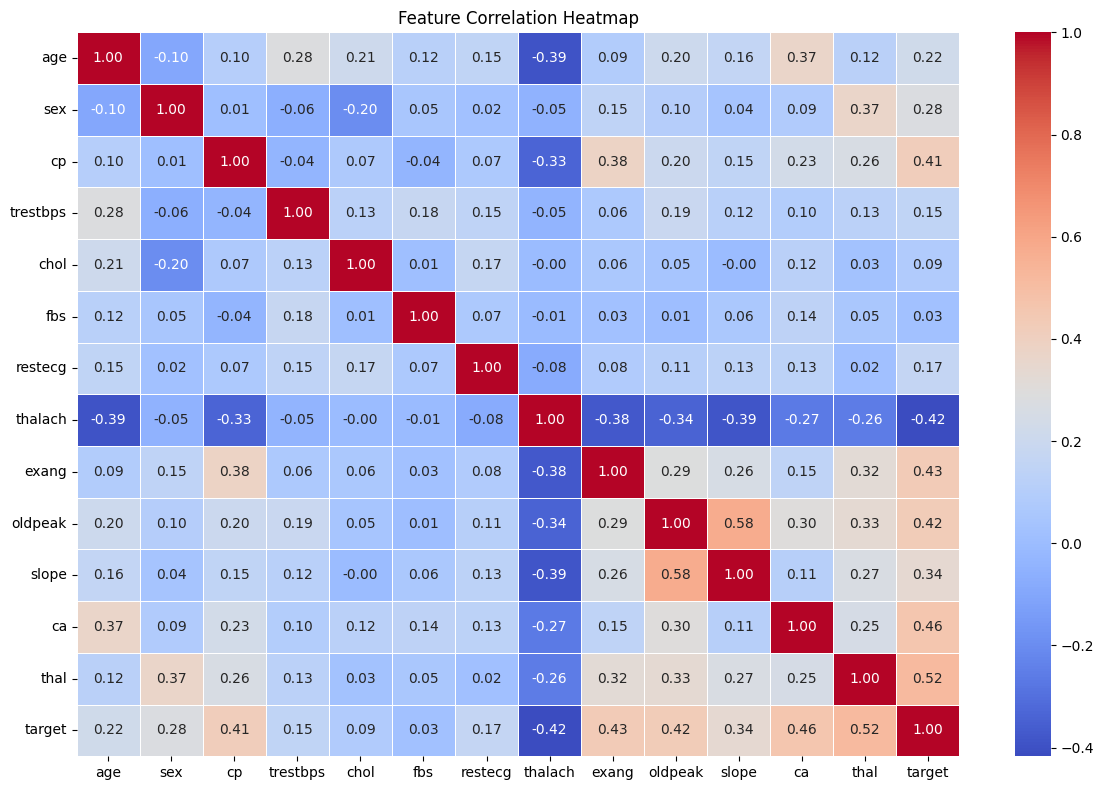

In [4]:
plt.figure(figsize=(12, 8))

corr = df.corr(numeric_only=True)
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


### Correlation notes

The heatmap is used for exploratory analysis only. Several variables show noticeable relationships with the target, but correlation alone does not establish causation or determine predictive usefulness. Model performance is evaluated separately on a held-out test set.


## 4. Features and train/test split


In [5]:
X = df.drop("target", axis=1)
y = df["target"]

numeric_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak",
]

categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal",
]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))
print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))


Training shape: (242, 13)
Testing shape: (61, 13)

Training target distribution:
target
0    0.541322
1    0.458678
Name: proportion, dtype: float64

Testing target distribution:
target
0    0.540984
1    0.459016
Name: proportion, dtype: float64


## 5. Preprocessing

Numeric features are median-imputed and standardized. Categorical features are imputed with the most frequent value and one-hot encoded. Keeping preprocessing inside each model pipeline helps avoid leakage from the test set.


In [6]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ]
)


## 6. Evaluation helper


In [7]:
def evaluate_model(name, model, X_test, y_test):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    }

    print(f"{name} Results")
    for metric, value in metrics.items():
        if metric != "Model":
            print(f"{metric}: {value:.4f}")

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, pred))

    print("\nClassification Report:")
    print(classification_report(y_test, pred))

    return metrics, pred, proba


## 7. Logistic Regression


In [8]:
log_reg_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000)),
    ]
)

log_reg_model.fit(X_train, y_train)
log_metrics, log_pred, log_proba = evaluate_model(
    "Logistic Regression",
    log_reg_model,
    X_test,
    y_test,
)


Logistic Regression Results
Accuracy: 0.8852
Precision: 0.8387
Recall: 0.9286
F1: 0.8814
ROC-AUC: 0.9665

Confusion Matrix:
[[28  5]
 [ 2 26]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



## 8. Random Forest


In [9]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(n_estimators=100, random_state=42)),
    ]
)

rf_model.fit(X_train, y_train)
rf_metrics, rf_pred, rf_proba = evaluate_model(
    "Random Forest",
    rf_model,
    X_test,
    y_test,
)


Random Forest Results
Accuracy: 0.8689
Precision: 0.8125
Recall: 0.9286
F1: 0.8667
ROC-AUC: 0.9426

Confusion Matrix:
[[27  6]
 [ 2 26]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.82      0.87        33
           1       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61



## 9. Gradient Boosting


In [10]:
gb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(random_state=42)),
    ]
)

gb_model.fit(X_train, y_train)
gb_metrics, gb_pred, gb_proba = evaluate_model(
    "Gradient Boosting",
    gb_model,
    X_test,
    y_test,
)


Gradient Boosting Results
Accuracy: 0.8689
Precision: 0.8125
Recall: 0.9286
F1: 0.8667
ROC-AUC: 0.9470

Confusion Matrix:
[[27  6]
 [ 2 26]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.82      0.87        33
           1       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61



## 10. Model comparison

The models are compared using several complementary metrics. In a health-risk classification setting, recall is especially useful because false negatives can be costly, while ROC-AUC provides a threshold-independent view of ranking performance.


In [11]:
results = pd.DataFrame([
    log_metrics,
    rf_metrics,
    gb_metrics,
]).sort_values(by="ROC-AUC", ascending=False)

results


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.885246,0.83871,0.928571,0.881356,0.966450
2,Gradient Boosting,0.868852,0.81250,0.928571,0.866667,0.946970
1,Random Forest,0.868852,0.81250,0.928571,0.866667,0.942641


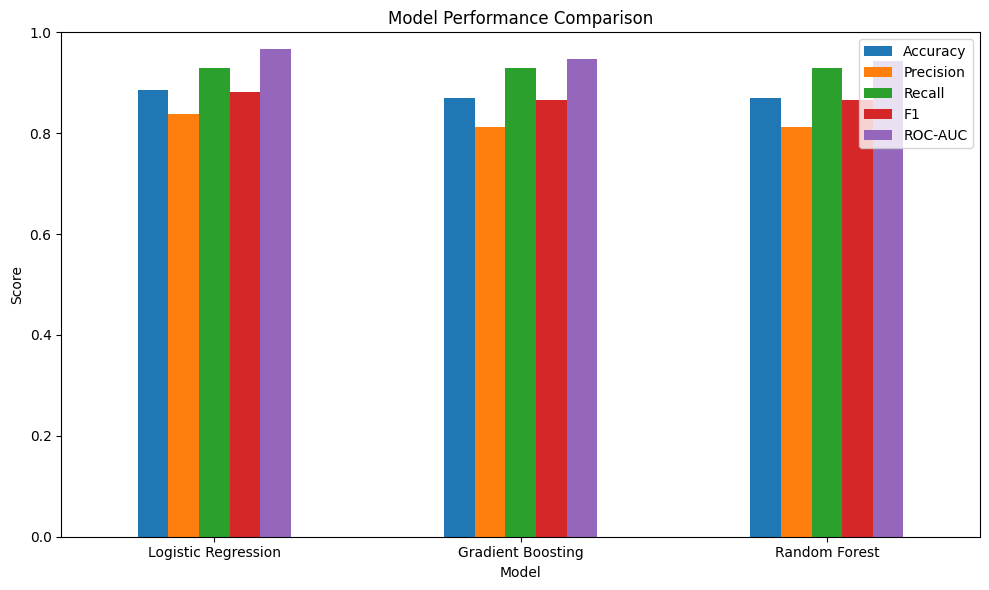

In [12]:
results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].plot(
    kind="bar",
    figsize=(10, 6),
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 11. Example prediction

This example demonstrates how the trained Random Forest pipeline can generate a class prediction and probability for one held-out sample.


In [13]:
sample = X_test.iloc[[0]]
prediction = rf_model.predict(sample)[0]
probability = rf_model.predict_proba(sample)[0, 1]

predicted_label = (
    "Heart Disease Present"
    if prediction == 1
    else "No Heart Disease"
)

print("Sample:")
print(sample.iloc[0].to_dict())

print("\nPrediction:", predicted_label)
print(f"Predicted probability of heart disease: {probability:.2%}")


Sample:
{'age': 59.0, 'sex': 1.0, 'cp': 3.0, 'trestbps': 138.0, 'chol': 271.0, 'fbs': 0.0, 'restecg': 2.0, 'thalach': 182.0, 'exang': 0.0, 'oldpeak': 0.0, 'slope': 0.0, 'ca': 0.0, 'thal': 1.0}

Prediction: No Heart Disease
Predicted probability of heart disease: 37.00%


## 12. Limitations

- The dataset is small, with 303 observations.
- Results depend on a single train/test split and should not be treated as clinical evidence.
- The dataset may not represent all patient populations equally.
- Hyperparameter tuning and cross-validation could provide a more robust comparison.
- Predictive association does not imply medical causation.

A natural next step would be stratified cross-validation and systematic hyperparameter tuning.
